#### Importing Dependencies

In [252]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

In [253]:
import pandas as pd
from datetime import datetime
from pathlib import Path
# -----------------------------------
# EXPERIMENT DETAILS FUNCTION
# -----------------------------------
def addRecord(rmse,r2_val,r2_train,changes,x_train,x_val):
    results_row = {
        "rmse": rmse,
        "r2_score_val": r2_val,
        "r2_score_train":r2_train,
        "timestamp": datetime.now(),
        "changes":changes,

        # useful extra columns
        "num_features": x_train.shape[1],
        "train_size": len(x_train),
        "val_size": len(x_val),
        "model": "LinearRegression"
    }
    results_path = "results.csv"

    if Path(results_path).exists():

        results_df = pd.read_csv(results_path)

        # auto increment id
        next_id = len(results_df) + 1

        results_row["id"] = next_id

        results_df = pd.concat(
            [
                results_df,
                pd.DataFrame([results_row])
            ],
            ignore_index=True
        )
    else:
        results_row["id"] = 1

        results_df = pd.DataFrame([results_row])

    results_df = results_df[
        [
            "id",
            "changes",
            "rmse",
            "r2_score_val",
            "r2_score_train",
            "num_features",
            "train_size",
            "val_size",
            "model",
            "timestamp"
        ]
    ]

    results_df.to_csv(
        results_path,
        index=False
    )

    print("\nResults saved to results.csv")


#### Loading Dataset

In [254]:
og_data = pd.read_csv("chicago_taxi_train.csv")

data = og_data.copy()
data.head()

,TRIP_START_TIMESTAMP,TRIP_END_TIMESTAMP,TRIP_START_HOUR,TRIP_SECONDS,TRIP_MILES,TRIP_SPEED,PICKUP_CENSUS_TRACT,DROPOFF_CENSUS_TRACT,PICKUP_COMMUNITY_AREA,DROPOFF_COMMUNITY_AREA,FARE,TIPS,TIP_RATE,TOLLS,EXTRAS,TRIP_TOTAL,PAYMENT_TYPE,COMPANY
0,05/17/2022 7:15:00 AM,05/17/2022 7:45:00 AM,7.25,2341,2.57,4.0,NaN,NaN,NaN,17.0,31.99,2.0,6.3,0.0,0.0,33.99,Mobile,Flash Cab
1,05/17/2022 5:15:00 PM,05/17/2022 5:30:00 PM,17.25,1074,1.18,4.0,NaN,1.703108e+10,NaN,8.0,9.75,3.0,27.9,0.0,1.0,14.25,Credit Card,Flash Cab
2,05/17/2022 5:15:00 PM,05/17/2022 5:30:00 PM,17.25,1173,1.29,4.0,1.703132e+10,1.703108e+10,32.0,8.0,10.25,0.0,0.0,0.0,0.0,10.25,Cash,Sun Taxi
3,05/17/2022 6:00:00 PM,05/17/2022 7:00:00 PM,18.00,3360,3.70,4.0,1.703132e+10,1.703124e+10,32.0,24.0,23.75,0.0,0.0,0.0,1.0,24.75,Cash,Choice Taxi Association
4,05/17/2022 5:00:00 PM,05/17/2022 5:30:00 PM,17.00,1044,1.15,4.0,1.703132e+10,1.703108e+10,32.0,8.0,10.00,0.0,0.0,0.0,0.0,10.00,Cash,Flash Cab


In [255]:
data.drop(['TRIP_START_TIMESTAMP','TRIP_END_TIMESTAMP','TRIP_START_HOUR','DROPOFF_CENSUS_TRACT',
           'PICKUP_CENSUS_TRACT','PAYMENT_TYPE','COMPANY','TIPS','TOLLS','EXTRAS','TRIP_TOTAL','TIP_RATE'],inplace=True,axis=1)
data.dropna(inplace=True)
data = pd.get_dummies(
    data,
    columns=[
        "PICKUP_COMMUNITY_AREA",
        "DROPOFF_COMMUNITY_AREA"
    ],
    drop_first=True,
    dtype=float
)


In [256]:
from sklearn.preprocessing import StandardScaler
log_features = ['TRIP_MILES','TRIP_SECONDS','TRIP_SPEED']

data[log_features] = np.log1p(data[log_features])

scaler = StandardScaler()

data[log_features] = scaler.fit_transform(data[log_features])

In [257]:
data[data.columns[:4]].describe()

,TRIP_SECONDS,TRIP_MILES,TRIP_SPEED,FARE
count,2.617000e+04,2.617000e+04,2.617000e+04,26170.000000
mean,-1.285873e-15,-2.780267e-16,2.780267e-16,21.371919
std,1.000019e+00,1.000019e+00,1.000019e+00,15.482348
min,-3.533991e+00,-1.535545e+00,-2.430142e+00,3.250000
25%,-7.739790e-01,-9.489656e-01,-8.060283e-01,8.500000
50%,1.136883e-02,-1.079893e-01,-1.014398e-01,14.750000
75%,8.414262e-01,9.738315e-01,8.034744e-01,33.750000
max,2.627939e+00,2.502453e+00,2.648432e+00,127.000000


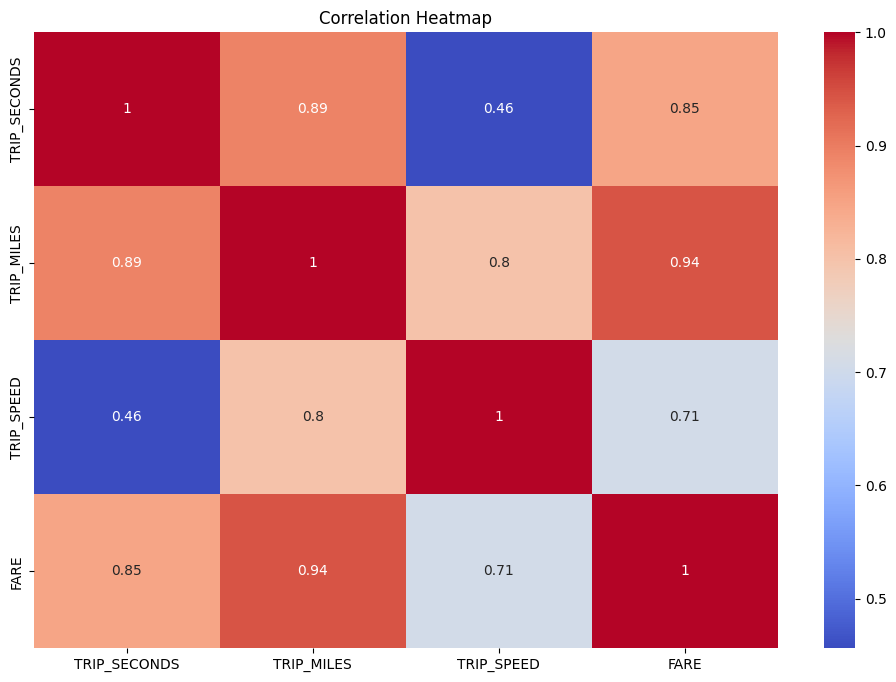

In [258]:
corr = data[data.columns[:4]].corr(numeric_only=True)
plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

#### Data Preprocessing

In [259]:
x = data.drop(['FARE'],axis=1)
y= data.FARE

In [260]:
from sklearn.preprocessing import PolynomialFeatures
import pandas as pd

poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

# Select columns
cols = x.columns[:3]

# Transform
x_poly = poly.fit_transform(x[cols])

# Feature names
feature_names = poly.get_feature_names_out(cols)

# DataFrame
x_poly_df = pd.DataFrame(
    x_poly,
    columns=feature_names,
    index=x.index
)

# Remove original columns to avoid duplicates
new_poly_cols = x_poly_df.drop(columns=cols)

# Add only new polynomial features
x = pd.concat([x, new_poly_cols], axis=1)

#### Splitting the data

In [261]:
from sklearn.model_selection import train_test_split

x_train_val, x_test, y_train_val, y_test = train_test_split(x,y,test_size=0.2,random_state=42)
x_train,x_val,y_train,y_val = train_test_split(x_train_val,y_train_val,test_size=0.2,random_state=42)

#### creating and training the Linear Regression Model

In [262]:
from sklearn.linear_model import Ridge,LinearRegression

model = Ridge(alpha=0.01)
model.fit(x_train,y_train)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",0.01
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [263]:
x_features = x.columns

coef_df = pd.DataFrame({
    "feature": x_features,
    "coefficient": model.coef_,
    "abs_coef": np.abs(model.coef_)
})

coef_df.sort_values(by="abs_coef",inplace=True)


In [264]:
threshold = 0.5

features_to_remove = coef_df[coef_df['abs_coef'] < threshold].feature

In [265]:
x_train = x_train.drop(columns=features_to_remove)
x_val = x_val.drop(columns=features_to_remove)
x_test = x_test.drop(columns=features_to_remove)

In [266]:
model.fit(x_train,y_train)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",0.01
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [267]:
from sklearn.metrics import root_mean_squared_error,r2_score

y_val_pred = model.predict(x_val)

rmse_val = root_mean_squared_error(
    y_val,
    y_val_pred
)

r2_score_val = r2_score(
    y_val,
    y_val_pred
)

print(f"Root Mean Squared Error: {rmse_val:.4f}")
print(f"R^2 Score: {r2_score_val:.4f}")
y_train_pred = model.predict(x_train)

train_rmse = root_mean_squared_error(
    y_train,
    y_train_pred
)

train_r2 = r2_score(
    y_train,
    y_train_pred
)

print(train_rmse)
print(train_r2)

addRecord(rmse=rmse_val,changes="Ridge alpha:0.01",r2_val=r2_score_val,r2_train=train_r2,x_train=x_train,x_val=x_val)


Root Mean Squared Error: 3.0839
R^2 Score: 0.9600
3.008330262817861
0.9624794378726528

Results saved to results.csv


#### plotting and analysis of Predictions

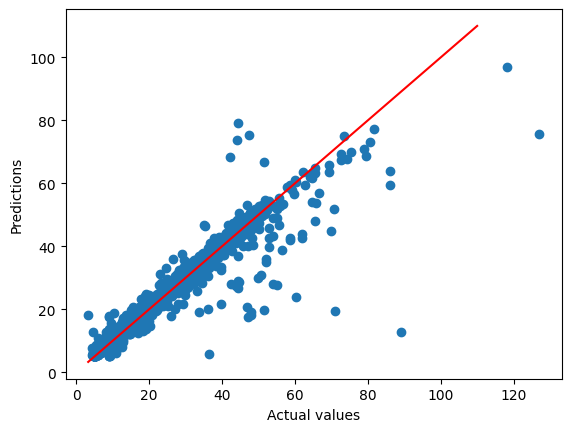

In [268]:
plt.scatter(y_val,y_val_pred)
plt.xlabel("Actual values")
plt.ylabel("Predictions")

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.show()

In [269]:

y_test_pred = model.predict(x_test)

rmse_val = root_mean_squared_error(
    y_test,
    y_test_pred
)

r2_score_val = r2_score(
    y_test,
    y_test_pred
)

print(f"Root Mean Squared Error: {rmse_val:.4f}")
print(f"R^2 Score: {r2_score_val:.4f}")

# addRecord(rmse=rmse_val,changes="Final Testing with test data",r2_val=r2_score_val,r2_train=train_r2,x_train=x_train,x_val=x_val)


Root Mean Squared Error: 3.0513
R^2 Score: 0.9606


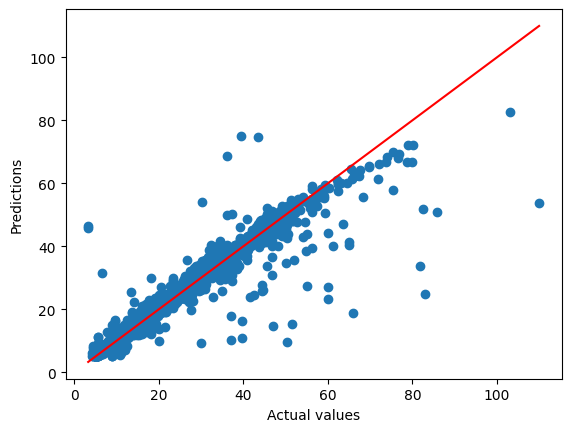

In [270]:
plt.scatter(y_test,y_test_pred)
plt.xlabel("Actual values")
plt.ylabel("Predictions")

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.show()